# Astronomy Campus background, sky-radiance and QBER contour maps

This notebook reproduces the three final figures from the original `lightsoff1truncated.xls` and `lightson1truncated.xls` datasets:

1. **Astronomy Campus Background Counts Contour**
2. **Astronomy Campus Background Sky Radiance Contour**
3. **Astronomy Campus QBER Contour**

## Assumptions used

- Detector dark count rate: **208 counts/s**
- Effective aperture diameter: **2.4 cm**
- Receiver FOV half-angle: **458 µrad**
- Bandpass filter centre wavelength: **830 nm**
- Filter spectral bandwidth: **10 nm**
- Detector photon-detection efficiency at 830 nm: **0.45**
- Detected QKD signal rate: **20 counts/s**
- QKD repetition rate: **2 MHz**
- Temporal acceptance window: **1 ns**
- Intrinsic signal error rate: **1%**
- Random background/dark detections are assumed to generate an erroneous bit with probability **1/2**
- QBER values above **11%** are highlighted in green.

For radiance, the detector dark count is subtracted. For QBER, the full measured count rate is retained because detector dark counts can still cause random accepted detections.

In [1]:
# If needed, install the dependencies once:
# %pip install numpy pandas matplotlib scipy xlrd

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.colors import LogNorm, Normalize
from matplotlib.ticker import FixedLocator, FuncFormatter
from matplotlib import colormaps

from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

## 1. Input files

Put the two original `.xls` files in the same folder as the notebook, or edit the paths below.

In [3]:
DATA_DIR = Path("D:\PhD Thesis Writing/astrocampusdata")

LIGHTS_OFF_FILE = DATA_DIR / "lightsoff1truncated.xls"
LIGHTS_ON_FILE = DATA_DIR / "lightson1truncated.xls"

OUTPUT_DIR = Path("qkd_contour_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def load_original_xls(path):
    return pd.read_excel(
        path,
        header=None,
        names=["counts_cps", "scan_deg", "orientation_deg"],
        engine="xlrd",
    )

data = {
    "lights_off": load_original_xls(LIGHTS_OFF_FILE),
    "lights_on": load_original_xls(LIGHTS_ON_FILE),
}

display(data["lights_off"].head())
display(data["lights_on"].head())

,counts_cps,scan_deg,orientation_deg
0,288.0,10,0
1,275.2,20,0
2,313.2,30,0
3,305.8,40,0
4,294.8,50,0


,counts_cps,scan_deg,orientation_deg
0,523.20,10,0
1,594.20,20,0
2,519.25,30,0
3,370.00,40,0
4,333.00,50,0


## 2. Experimental and model parameters

In [20]:
# Detector / optical receiver
DARK_CPS = 208.0
APERTURE_DIAMETER_M = 0.024
FOV_HALF_ANGLE_RAD = 458e-6
FILTER_CENTRE_NM = 830.0
FILTER_BANDWIDTH_NM = 10.0
DETECTOR_PDE = 0.45

# Simple QBER model
SIGNAL_CPS = 10.0
F_REP_HZ = 2e6
TIMING_WINDOW_S = 1e-9
E_SIG = 0.01
QBER_THRESHOLD_PERCENT = 11.0

# Plot settings
CMAP_NAME = "magma"
N_CONTOUR_LEVELS = 40
INTERPOLATION_GRID = 500
SMOOTHING_SIGMA = 6

# Derived receiver quantities
APERTURE_AREA_M2 = np.pi * (APERTURE_DIAMETER_M / 2)**2
SOLID_ANGLE_SR = np.pi * FOV_HALF_ANGLE_RAD**2

print(f"Aperture area = {APERTURE_AREA_M2:.4e} m^2")
print(f"Receiver solid angle = {SOLID_ANGLE_SR:.4e} sr")

Aperture area = 4.5239e-04 m^2
Receiver solid angle = 6.5899e-07 sr


## 3. Derived quantities

The sky-background count rate used for radiance is

\[
R_{\rm sky}=\max(R_{\rm meas}-R_{\rm dark},0).
\]

The estimated photon spectral radiance is

\[
L_\lambda =
\frac{R_{\rm sky}}
{A\,\Omega\,\Delta\lambda\,\eta_d}.
\]

The background/dark rate surviving the QKD timing window is

\[
B=R_{\rm meas}f_{\rm rep}\tau.
\]

The simple QBER model is

\[
{\rm QBER}=
\frac{e_{\rm sig}S+\frac12B}{S+B}.
\]

In [8]:
def add_derived_quantities(df):
    out = df.copy()

    # Optical sky background only
    out["sky_counts_cps"] = np.clip(out["counts_cps"] - DARK_CPS, 0, None)

    # Noise/dark detections inside accepted QKD timing windows
    out["accepted_noise_cps"] = (
        out["counts_cps"] * F_REP_HZ * TIMING_WINDOW_S
    )

    # Simple QBER estimate
    out["qber_pct"] = (
        (
            E_SIG * SIGNAL_CPS
            + 0.5 * out["accepted_noise_cps"]
        )
        /
        (
            SIGNAL_CPS
            + out["accepted_noise_cps"]
        )
        * 100.0
    )

    # Estimated incident photon spectral radiance
    out["radiance_ph"] = (
        out["sky_counts_cps"]
        /
        (
            APERTURE_AREA_M2
            * SOLID_ANGLE_SR
            * FILTER_BANDWIDTH_NM
            * DETECTOR_PDE
        )
    )

    return out

data = {name: add_derived_quantities(df) for name, df in data.items()}

## 4. Sky projection and interpolation

The centre of the circular plot is zenith and the outer circle is the horizon. The smooth field between measured directions is interpolated for visualisation.

In [10]:
def sky_xy(df):
    t = np.deg2rad(df["scan_deg"].to_numpy() - 90.0)
    a = np.deg2rad(df["orientation_deg"].to_numpy())

    x = np.sin(t) * np.sin(a)
    y = np.sin(t) * np.cos(a)

    return x, y


def interp_sky(df, value_col, n=INTERPOLATION_GRID):
    x, y = sky_xy(df)
    z = df[value_col].to_numpy()

    gx = np.linspace(-1.0, 1.0, n)
    gy = np.linspace(-1.0, 1.0, n)
    X, Y = np.meshgrid(gx, gy)

    mask = X**2 + Y**2 <= 1.0
    points = np.column_stack([x, y])

    Z_linear = griddata(points, z, (X, Y), method="linear")
    Z_nearest = griddata(points, z, (X, Y), method="nearest")
    Z = np.where(np.isnan(Z_linear), Z_nearest, Z_linear)

    # Smooth while respecting the circular mask
    Z_masked = np.where(mask, Z, 0.0)
    W = mask.astype(float)

    Z_smooth = gaussian_filter(Z_masked, sigma=SMOOTHING_SIGMA)
    W_smooth = gaussian_filter(W, sigma=SMOOTHING_SIGMA)

    Z = Z_smooth / np.maximum(W_smooth, 1e-12)

    # Keep interpolation within the measured extrema
    Z = np.clip(Z, np.nanmin(z), np.nanmax(z))
    Z[~mask] = np.nan

    return X, Y, Z


def decorate_sky_axes(ax):
    ax.add_patch(
        Circle((0, 0), 1.0, fill=False, linewidth=1.0, edgecolor="black")
    )

    for radius in [
        np.sin(np.deg2rad(60)),
        np.sin(np.deg2rad(30)),
    ]:
        ax.add_patch(
            Circle(
                (0, 0),
                radius,
                fill=False,
                linewidth=0.65,
                linestyle="--",
                edgecolor="black",
                alpha=0.7,
            )
        )

    ax.text(0, 1.035, "N", ha="center", va="bottom", fontsize=11)
    ax.text(1.06, 0, "E", ha="left", va="center", fontsize=11)
    ax.text(0, -1.06, "S", ha="center", va="top", fontsize=11)
    ax.text(-1.06, 0, "W", ha="right", va="center", fontsize=11)

    ax.text(
        0,
        np.sin(np.deg2rad(60)) + 0.015,
        "30°",
        ha="center",
        va="bottom",
        fontsize=10,
    )

    ax.set_aspect("equal")
    ax.set_xlim(-1.08, 1.08)
    ax.set_ylim(-1.08, 1.08)
    ax.axis("off")

## 5. Colour-bar formatting

In [12]:
def counts_formatter(x, pos):
    return f"{x:.0f}"


def scientific_formatter(x, pos):
    if x == 0:
        return "0"

    exponent = int(np.floor(np.log10(abs(x))))
    coefficient = x / 10**exponent

    if np.isclose(coefficient, 1):
        return rf"$10^{{{exponent}}}$"

    if np.isclose(coefficient, round(coefficient)):
        coefficient = int(round(coefficient))
        return rf"${coefficient}\times10^{{{exponent}}}$"

    return rf"${coefficient:.1f}\times10^{{{exponent}}}$"

## 6. Paired log-scale plotting function

In [14]:
def draw_pair_log(
    value_col,
    figure_title,
    colorbar_label,
    output_filename,
    ticks,
    tick_formatter,
    parameter_legend=None,
):
    vmin = min(
        data["lights_off"][value_col].min(),
        data["lights_on"][value_col].min(),
    )
    vmax = max(
        data["lights_off"][value_col].max(),
        data["lights_on"][value_col].max(),
    )
    vmin = max(vmin, 1e-12)

    levels = np.geomspace(vmin, vmax, N_CONTOUR_LEVELS)
    norm = LogNorm(vmin=vmin, vmax=vmax)

    figure_height = 7.2 if parameter_legend else 6.4
    fig = plt.figure(figsize=(14.5, figure_height))

    grid = fig.add_gridspec(
        1,
        3,
        width_ratios=[1, 1, 0.10],
        left=0.05,
        right=0.93,
        top=0.86,
        bottom=0.18 if parameter_legend else 0.08,
        wspace=0.30,
    )

    axes = [
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
    ]
    cax = fig.add_subplot(grid[0, 2])

    contour = None

    for ax, state, subtitle in zip(
        axes,
        ["lights_off", "lights_on"],
        ["Lights off", "Lights on"],
    ):
        X, Y, Z = interp_sky(data[state], value_col)

        contour = ax.contourf(
            X,
            Y,
            Z,
            levels=levels,
            cmap=CMAP_NAME,
            norm=norm,
            extend="both",
        )

        ax.contour(
            X,
            Y,
            Z,
            levels=8,
            colors="white",
            linewidths=0.22,
            alpha=0.25,
        )

        decorate_sky_axes(ax)
        ax.set_title(subtitle, fontsize=13, pad=18)

    colorbar = fig.colorbar(contour, cax=cax)
    colorbar.set_label(colorbar_label, fontsize=11)
    colorbar.ax.tick_params(labelsize=10)
    colorbar.locator = FixedLocator(ticks)
    colorbar.formatter = FuncFormatter(tick_formatter)
    colorbar.update_ticks()

    fig.suptitle(figure_title, fontsize=15, y=0.96)

    if parameter_legend is not None:
        fig.text(
            0.5,
            0.06,
            parameter_legend,
            ha="center",
            va="center",
            fontsize=10,
            bbox=dict(
                boxstyle="round,pad=0.45",
                facecolor="white",
                edgecolor="black",
                alpha=0.95,
            ),
        )

    output_path = OUTPUT_DIR / output_filename
    fig.savefig(output_path, dpi=220, bbox_inches="tight")
    plt.show()

    return output_path

## 7. QBER plot with a solid green region above 11%

In [16]:
def draw_qber_pair(
    output_filename="astronomy_campus_qber_contour.png",
):
    qber_min = 1.0
    threshold = QBER_THRESHOLD_PERCENT

    levels = np.linspace(
        qber_min,
        threshold,
        N_CONTOUR_LEVELS,
    )

    qber_cmap = colormaps.get_cmap(CMAP_NAME).copy()
    qber_cmap.set_over("limegreen")

    norm = Normalize(vmin=qber_min, vmax=threshold)

    fig = plt.figure(figsize=(14.5, 7.2))

    grid = fig.add_gridspec(
        1,
        3,
        width_ratios=[1, 1, 0.10],
        left=0.05,
        right=0.93,
        top=0.86,
        bottom=0.18,
        wspace=0.30,
    )

    axes = [
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
    ]
    cax = fig.add_subplot(grid[0, 2])

    contour = None

    for ax, state, subtitle in zip(
        axes,
        ["lights_off", "lights_on"],
        ["Lights off", "Lights on"],
    ):
        X, Y, Z = interp_sky(data[state], "qber_pct")

        contour = ax.contourf(
            X,
            Y,
            Z,
            levels=levels,
            cmap=qber_cmap,
            norm=norm,
            extend="max",
        )

        # Mark the 11% threshold boundary when it exists.
        if np.nanmin(Z) <= threshold <= np.nanmax(Z):
            ax.contour(
                X,
                Y,
                Z,
                levels=[threshold],
                colors="cyan",
                linewidths=1.1,
                alpha=0.95,
            )

        ax.contour(
            X,
            Y,
            Z,
            levels=8,
            colors="white",
            linewidths=0.18,
            alpha=0.16,
        )

        decorate_sky_axes(ax)
        ax.set_title(subtitle, fontsize=13, pad=18)

    colorbar = fig.colorbar(
        contour,
        cax=cax,
        extend="max",
    )

    colorbar.set_label("QBER (%)", fontsize=11)
    colorbar.set_ticks(np.arange(1, threshold + 1, 1))
    colorbar.ax.tick_params(labelsize=10)

    colorbar.ax.text(
        2.1,
        1.02,
        ">11%",
        transform=colorbar.ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=10,
    )

    fig.suptitle(
        "Astronomy Campus QBER Contour",
        fontsize=15,
        y=0.96,
    )

    qber_legend = (
        f"QBER parameters: signal count rate = {SIGNAL_CPS:g} counts/s; "
        f"repetition rate = {F_REP_HZ/1e6:g} MHz; "
        f"timing window = {TIMING_WINDOW_S*1e9:g} ns; "
        f"intrinsic signal error = {100*E_SIG:g}%; "
        f"dark/noise counts included in measured count rate. "
        r"QBER = "
        r"$\dfrac{e_{\rm sig}S+\frac{1}{2}R_{\rm meas}f_{\rm rep}\tau}"
        r"{S+R_{\rm meas}f_{\rm rep}\tau}$."
    )

    fig.text(
        0.5,
        0.06,
        qber_legend,
        ha="center",
        va="center",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.45",
            facecolor="white",
            edgecolor="black",
            alpha=0.95,
        ),
    )

    output_path = OUTPUT_DIR / output_filename
    fig.savefig(output_path, dpi=220, bbox_inches="tight")
    plt.show()

    return output_path

## 8. Produce the three final figures

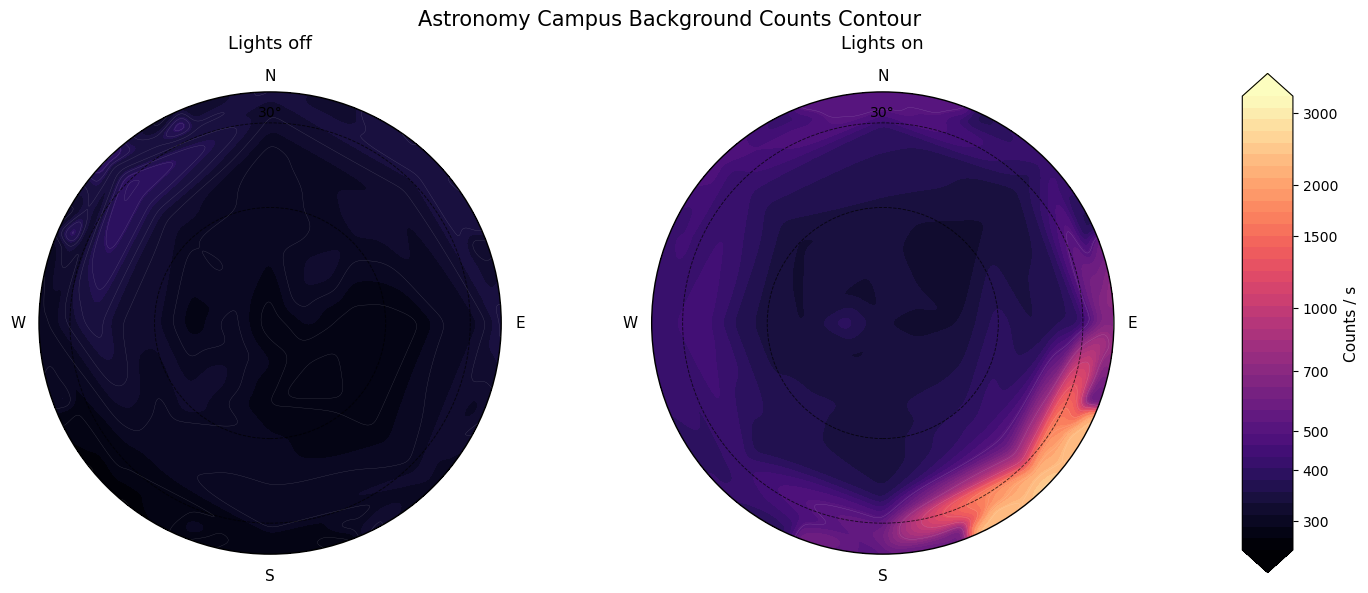

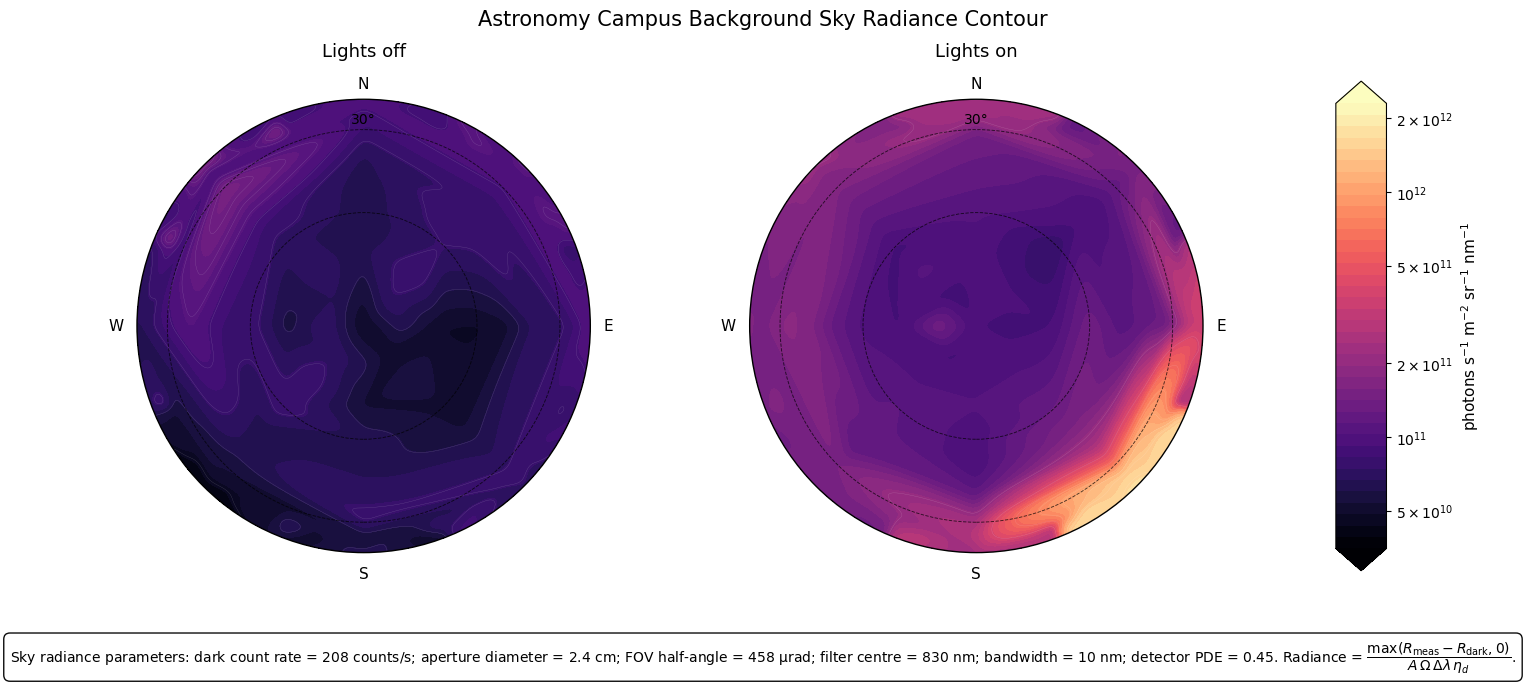

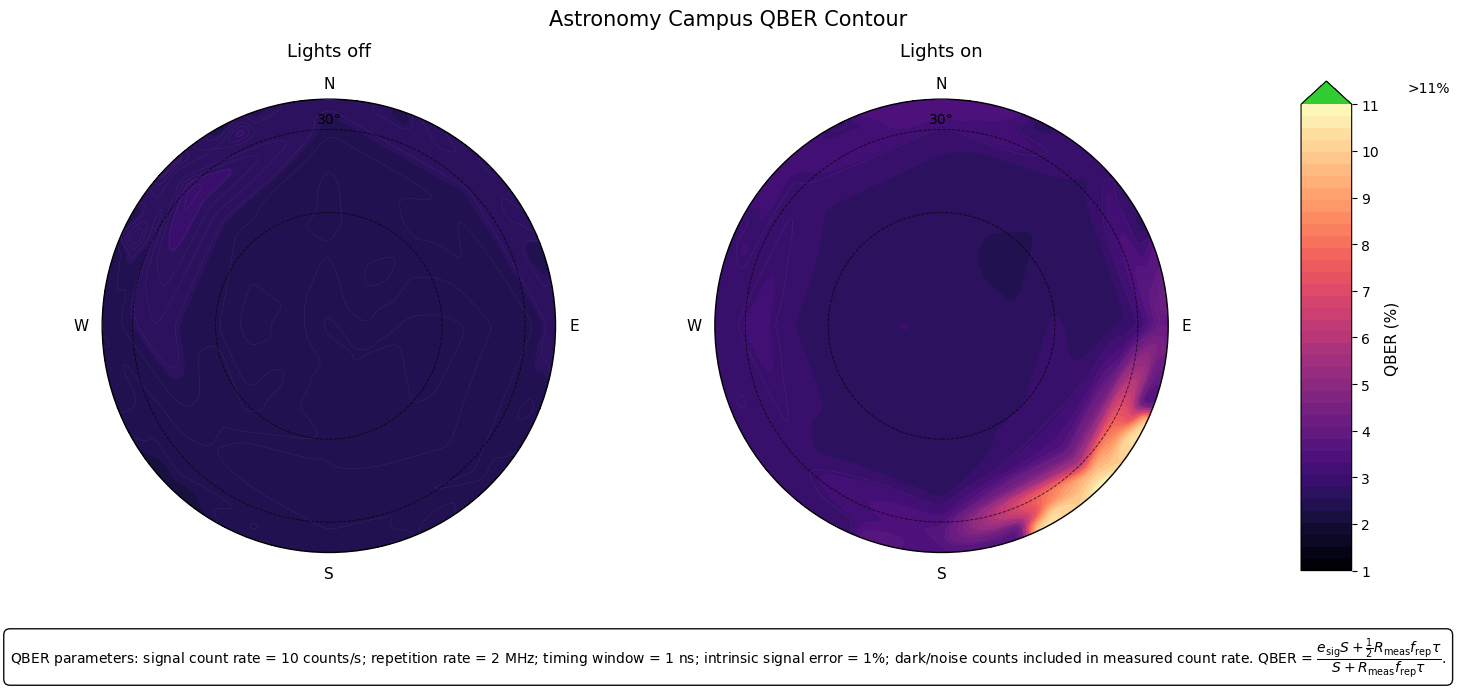

Saved:
qkd_contour_outputs\astronomy_campus_background_counts_contour.png
qkd_contour_outputs\astronomy_campus_background_sky_radiance_contour.png
qkd_contour_outputs\astronomy_campus_qber_contour.png


In [22]:
# 1. Background count contour
counts_plot = draw_pair_log(
    value_col="counts_cps",
    figure_title="Astronomy Campus Background Counts Contour",
    colorbar_label="Counts / s",
    output_filename="astronomy_campus_background_counts_contour.png",
    ticks=[300, 400, 500, 700, 1000, 1500, 2000, 3000],
    tick_formatter=counts_formatter,
)


# 2. Sky-radiance contour
radiance_legend = (
    f"Sky radiance parameters: dark count rate = {DARK_CPS:g} counts/s; "
    f"aperture diameter = {APERTURE_DIAMETER_M*100:g} cm; "
    f"FOV half-angle = {FOV_HALF_ANGLE_RAD*1e6:g} μrad; "
    f"filter centre = {FILTER_CENTRE_NM:g} nm; "
    f"bandwidth = {FILTER_BANDWIDTH_NM:g} nm; "
    f"detector PDE = {DETECTOR_PDE:g}. "
    r"Radiance = "
    r"$\dfrac{\max(R_{\rm meas}-R_{\rm dark},0)}"
    r"{A\,\Omega\,\Delta\lambda\,\eta_d}$."
)

radiance_plot = draw_pair_log(
    value_col="radiance_ph",
    figure_title="Astronomy Campus Background Sky Radiance Contour",
    colorbar_label=r"photons s$^{-1}$ m$^{-2}$ sr$^{-1}$ nm$^{-1}$",
    output_filename="astronomy_campus_background_sky_radiance_contour.png",
    ticks=[5e10, 1e11, 2e11, 5e11, 1e12, 2e12],
    tick_formatter=scientific_formatter,
    parameter_legend=radiance_legend,
)


# 3. QBER contour
qber_plot = draw_qber_pair()


print("Saved:")
print(counts_plot)
print(radiance_plot)
print(qber_plot)

## Notes

To explore different QKD assumptions, edit the parameter cell and rerun the notebook. For example:

```python
SIGNAL_CPS = 50.0
E_SIG = 0.02
TIMING_WINDOW_S = 2e-9
```

The radiance estimate currently corrects for detector PDE only. If measured optical throughput becomes available for the FL830-10 filter, GBE, collimator, windows, or other receiver components, include those transmission factors in the denominator of the radiance expression.